## Tune the number of layers and neurons in the network by systematically testing multiple architectures, manually tracking performance metrics, and applying advanced optimization techniques like Bayesian hyperparameter tuning.

In [1]:
import time, math
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rg = np.random.default_rng(0)
n = 3000
t = np.sqrt(rg.uniform(0.05, 1, n)) * 3 * np.pi
cls = rg.integers(0, 2, n)
spiral = np.c_[t * np.cos(t + cls * np.pi), t * np.sin(t + cls * np.pi)] + rg.normal(0, 0.6, (n, 2))
X = np.c_[spiral, rg.normal(size=(n, 8))]; y = cls

idx = rg.permutation(n); tr, va, te = idx[:1800], idx[1800:2400], idx[2400:]
mu_, sd_ = X[tr].mean(0), X[tr].std(0); X = (X - mu_) / sd_      
print('train/val/test:', len(tr), len(va), len(te))

train/val/test: 1800 600 600


In [3]:
def softmax_ce(logits, yy):
    z = logits - logits.max(1, keepdims=True); p = np.exp(z); p /= p.sum(1, keepdims=True)
    return -np.mean(np.log(p[np.arange(len(yy)), yy] + 1e-12)), p

def train_mlp(layers, width, seed, epochs=80, bs=64, lr=0.03, mom=0.9):
    r = np.random.default_rng(seed); sizes = [X.shape[1]] + [width] * layers + [2]
    W = [r.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]   
    B = [np.zeros(b) for b in sizes[1:]]
    VW, VB = [np.zeros_like(w) for w in W], [np.zeros_like(b) for b in B]

    def forward(x):
        acts = [x]
        for i in range(len(W)):
            x = x @ W[i] + B[i]
            if i < len(W) - 1: x = np.maximum(x, 0)                 
            acts.append(x)
        return acts

    best = None
    for ep in range(epochs):
        perm = r.permutation(tr)
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; acts = forward(X[b]); _, d = softmax_ce(acts[-1], y[b])
            d[np.arange(len(b)), y[b]] -= 1; d /= len(b)             
            for k in reversed(range(len(W))):                      
                gW, gB = acts[k].T @ d, d.sum(0)
                if k > 0: d = (d @ W[k].T) * (acts[k] > 0)
                VW[k] = mom * VW[k] - lr * gW; VB[k] = mom * VB[k] - lr * gB
                W[k] += VW[k]; B[k] += VB[k]
        val_loss, _ = softmax_ce(forward(X[va])[-1], y[va])
        if best is None or val_loss < best['val_loss']:              
            lv, lt = forward(X[va])[-1], forward(X[te])[-1]
            best = dict(val_loss=val_loss, val_acc=np.mean(lv.argmax(1) == y[va]),
                        test_loss=softmax_ce(lt, y[te])[0], test_acc=np.mean(lt.argmax(1) == y[te]), epoch=ep)
    best['params'] = sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))
    return best

In [4]:
layer_opts, width_opts = [1, 2, 3, 4], [4, 8, 16, 32, 64, 128]
log, t0 = [], time.time()
for L in layer_opts:
    for w in width_opts:
        runs = [train_mlp(L, w, seed) for seed in range(3)]
        log.append(dict(layers=L, width=w, params=runs[0]['params'],
                        **{k: np.mean([r[k] for r in runs]) for k in ['val_loss', 'val_acc', 'test_acc', 'epoch']}))
print(f'{len(log)} architectures x 3 seeds in {time.time() - t0:.0f}s')

print(f"{'Layers':>6s} {'Width':>6s} {'Params':>8s} {'Val loss':>9s} {'Val acc':>8s} {'Best epoch':>11s}")
for r in sorted(log, key=lambda r: r['val_loss'])[:8]:
    print(f"{r['layers']:6d} {r['width']:6d} {r['params']:8d} {r['val_loss']:9.3f} {r['val_acc']:8.3f} {r['epoch']:11.0f}")
print('... worst:', [(r['layers'], r['width'], round(r['val_loss'], 2)) for r in sorted(log, key=lambda r: -r['val_loss'])[:3]])

24 architectures x 3 seeds in 98s
Layers  Width   Params  Val loss  Val acc  Best epoch
     3      8      250     0.030    0.989          68
     4     16     1026     0.036    0.986          61
     2      8      178     0.037    0.985          76
     2     16      482     0.037    0.987          74
     3     16      754     0.042    0.986          53
     4      8      322     0.061    0.981          76
     3     32     2530     0.150    0.953          44
     4     32     3586     0.156    0.947          45
... worst: [(3, 128, np.float64(0.58)), (4, 128, np.float64(0.55)), (2, 128, np.float64(0.52))]


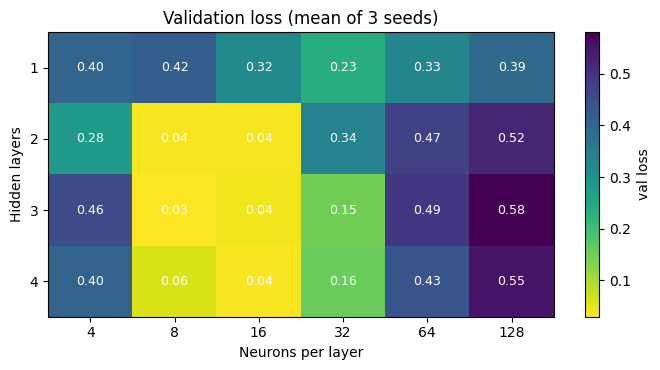

In [5]:
grid = np.array([[next(r['val_loss'] for r in log if r['layers'] == L and r['width'] == w)
                  for w in width_opts] for L in layer_opts])
plt.figure(figsize=(7, 3.8)); plt.imshow(grid, cmap='viridis_r', aspect='auto')
for i in range(len(layer_opts)):
    for j in range(len(width_opts)):
        plt.text(j, i, f'{grid[i, j]:.2f}', ha='center', va='center', color='w', fontsize=9)
plt.xticks(range(len(width_opts)), width_opts); plt.yticks(range(len(layer_opts)), layer_opts)
plt.xlabel('Neurons per layer'); plt.ylabel('Hidden layers'); plt.title('Validation loss (mean of 3 seeds)')
plt.colorbar(label='val loss'); plt.tight_layout(); plt.show()

In [6]:
cands = [(L, w) for L in layer_opts for w in width_opts]
score = {(r['layers'], r['width']): r['val_loss'] for r in log}    
enc = lambda c: np.array([(c[0] - 1) / 3, (math.log2(c[1]) - 2) / 5])   

def rbf(A, B, ls):
    d2 = ((A[:, None, :] - B[None, :, :]) ** 2).sum(2)
    return np.exp(-0.5 * d2 / ls ** 2)

def gp_predict(Xo, yo, Xq, noise=1e-2):
    ym, ys = yo.mean(), yo.std() + 1e-9; z = (yo - ym) / ys              
    best = None
    for ls in [0.15, 0.25, 0.4, 0.7, 1.2]:                             
        L = np.linalg.cholesky(rbf(Xo, Xo, ls) + noise * np.eye(len(Xo)))
        a = np.linalg.solve(L.T, np.linalg.solve(L, z))
        ll = -0.5 * z @ a - np.log(np.diag(L)).sum()
        if best is None or ll > best[0]: best = (ll, ls, L, a)
    _, ls, L, a = best
    Ks = rbf(Xq, Xo, ls); mu = Ks @ a
    v = np.linalg.solve(L, Ks.T); var = np.maximum(1 - (v ** 2).sum(0), 1e-12)
    return mu * ys + ym, np.sqrt(var) * ys                             

def norm_pdf(z): return np.exp(-0.5 * z ** 2) / np.sqrt(2 * np.pi)
def norm_cdf(z): return 0.5 * (1 + np.vectorize(math.erf)(z / np.sqrt(2)))

def next_by_ei(observed):
    Xo = np.array([enc(c) for c in observed]); yo = np.array([score[c] for c in observed])
    left = [c for c in cands if c not in observed]
    mu, sd = gp_predict(Xo, yo, np.array([enc(c) for c in left]))
    z = (yo.min() - mu) / sd                                            
    ei = (yo.min() - mu) * norm_cdf(z) + sd * norm_pdf(z)
    return left[int(np.argmax(ei))], ei.max()

In [7]:
rs = np.random.default_rng(0)
observed = [cands[i] for i in rs.choice(len(cands), 4, replace=False)]  
for c in observed: print(f'init  {str(c):9s} val loss = {score[c]:.3f}')
for step in range(6):
    c, ei = next_by_ei(observed); observed.append(c)
    print(f'BO #{step + 1}  {str(c):9s} val loss = {score[c]:.3f}  (EI = {ei:.3f}, best so far = {min(score[o] for o in observed):.3f})')
bo_choice = min(observed, key=lambda c: score[c])
print('BO choice:', bo_choice, '| grid best:', min(score, key=score.get))

init  (2, 4)    val loss = 0.284
init  (2, 128)  val loss = 0.523
init  (3, 128)  val loss = 0.580
init  (3, 16)   val loss = 0.042
BO #1  (3, 8)    val loss = 0.030  (EI = 0.027, best so far = 0.030)
BO #2  (4, 8)    val loss = 0.061  (EI = 0.047, best so far = 0.030)
BO #3  (4, 16)   val loss = 0.036  (EI = 0.012, best so far = 0.030)
BO #4  (1, 16)   val loss = 0.320  (EI = 0.007, best so far = 0.030)
BO #5  (3, 4)    val loss = 0.455  (EI = 0.002, best so far = 0.030)
BO #6  (4, 32)   val loss = 0.156  (EI = 0.022, best so far = 0.030)
BO choice: (3, 8) | grid best: (3, 8)


Budget        BO regret    Random regret
     4     0.088+-0.023     0.088+-0.023
     6     0.025+-0.011     0.042+-0.013
     8     0.009+-0.007     0.029+-0.010
    10     0.002+-0.001     0.012+-0.004
bo     : global best found = 80% | top-3 found = 97%
random : global best found = 20% | top-3 found = 70%


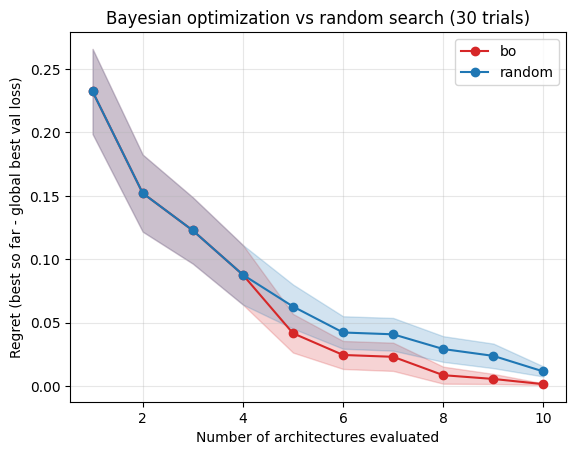

In [8]:
def run_search(method, seed, budget=10, n_init=4):
    r = np.random.default_rng(seed)
    obs = [cands[i] for i in r.choice(len(cands), n_init, replace=False)]
    while len(obs) < budget:
        if method == 'bo': obs.append(next_by_ei(obs)[0])
        else:
            left = [c for c in cands if c not in obs]
            obs.append(left[r.integers(len(left))])              
    return np.minimum.accumulate([score[c] for c in obs]), obs

g_best = min(score.values()); ranked = sorted(score.values())
res = {m: [run_search(m, s) for s in range(30)] for m in ['bo', 'random']}
regret = {m: np.array([curve - g_best for curve, _ in res[m]]) for m in res}

print(f"{'Budget':>6s} {'BO regret':>16s} {'Random regret':>16s}")
for b in [4, 6, 8, 10]:
    f = lambda m: f"{regret[m][:, b-1].mean():.3f}+-{regret[m][:, b-1].std(ddof=1)/np.sqrt(30):.3f}"
    print(f'{b:6d} {f("bo"):>16s} {f("random"):>16s}')
for m in res:
    hit = np.mean([min(score[c] for c in obs) == g_best for _, obs in res[m]])
    top3 = np.mean([min(score[c] for c in obs) <= ranked[2] for _, obs in res[m]])
    print(f'{m:7s}: global best found = {hit:.0%} | top-3 found = {top3:.0%}')

xs = np.arange(1, 11)
for m, col in [('bo', 'tab:red'), ('random', 'tab:blue')]:
    mean, se = regret[m].mean(0), regret[m].std(0, ddof=1) / np.sqrt(30)
    plt.plot(xs, mean, color=col, marker='o', label=m); plt.fill_between(xs, mean - se, mean + se, color=col, alpha=0.2)
plt.xlabel('Number of architectures evaluated'); plt.ylabel('Regret (best so far - global best val loss)')
plt.title('Bayesian optimization vs random search (30 trials)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [9]:
grid_best = min(score, key=score.get)
rows = [('Grid best', grid_best), ('BO choice', bo_choice), ('Baseline 1x16', (1, 16)), ('Biggest 4x128', (4, 128))]
print(f"{'Name':14s} {'Arch':8s} {'Params':>7s} {'Test acc':>14s} {'Test loss':>14s}")
for name, (L, w) in rows:
    rr = [train_mlp(L, w, 100 + s) for s in range(5)]
    acc, tl = [r['test_acc'] for r in rr], [r['test_loss'] for r in rr]
    print(f"{name:14s} {str((L, w)):8s} {rr[0]['params']:7d} {np.mean(acc):.3f}+-{np.std(acc):.3f}  {np.mean(tl):.3f}+-{np.std(tl):.3f}")

Name           Arch      Params       Test acc      Test loss
Grid best      (3, 8)       250 0.968+-0.005  0.091+-0.021
BO choice      (3, 8)       250 0.968+-0.005  0.091+-0.021
Baseline 1x16  (1, 16)      210 0.906+-0.022  0.220+-0.035
Biggest 4x128  (4, 128)   51202 0.795+-0.074  0.549+-0.087
